# Air Quality Prediction — Data Inspection & EDA

**Purpose:** Understand the `../data/../data/city_day.csv` dataset before moving into machine learning.

This notebook covers the first data-focused stages of the project:
1. Inspect the dataset and its columns.
2. Investigate missing values and duplicates.
3. Summarize pollutant and AQI distributions.
4. Compare AQI across cities.
5. Explore pollutant correlations.
6. Explore monthly and yearly trends.
7. Create useful date features.

**Important:** This is exploratory analysis, not model training. We are not filling all missing values or choosing model features yet. Those decisions should be made with a clear purpose later.

**How to use:** Put `../data/city_day.csv` in the same folder as this notebook, or upload it to the current Colab session. Then run cells from top to bottom.

## 1. Load the data

A **row** is an observation; a **column** is a variable. In this file, each row is intended to represent a city's daily air-quality record.

Pandas is used to handle tables. NumPy is useful for numerical operations. Matplotlib and Seaborn help us visualize patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# If the file is in the same folder as this notebook:
df = pd.read_csv("../data/city_day.csv")

# Convert Date from text to a proper datetime type.
# Invalid dates become NaT so they can be detected.
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Shape (rows, columns):", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of cities:", df["City"].nunique())

display(df.head())
display(df.dtypes.to_frame("data_type"))

Shape (rows, columns): (29531, 16)
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Number of cities: 26


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


,data_type
City,str
Date,datetime64[us]
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64


### What the initial inspection tells us

For the supplied file, the shape is **29,531 rows × 16 columns**, with **26 cities** and dates from **2015-01-01** to **2020-07-01**.

The columns include city and date identifiers, pollutant measurements (`PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, `Toluene`, `Xylene`), and the AQI value and category (`AQI`, `AQI_Bucket`).

`Date` should be stored as datetime, not plain text, so sorting and extracting year/month/weekday are reliable.

## 2. Data quality: missing values

A missing value means a measurement was not recorded or is unavailable in this file. It does **not** mean the pollutant concentration was zero.

We will report both counts and percentages. We will not automatically delete every row with a missing value; that could discard a lot of useful data.

,missing_count,missing_percent
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


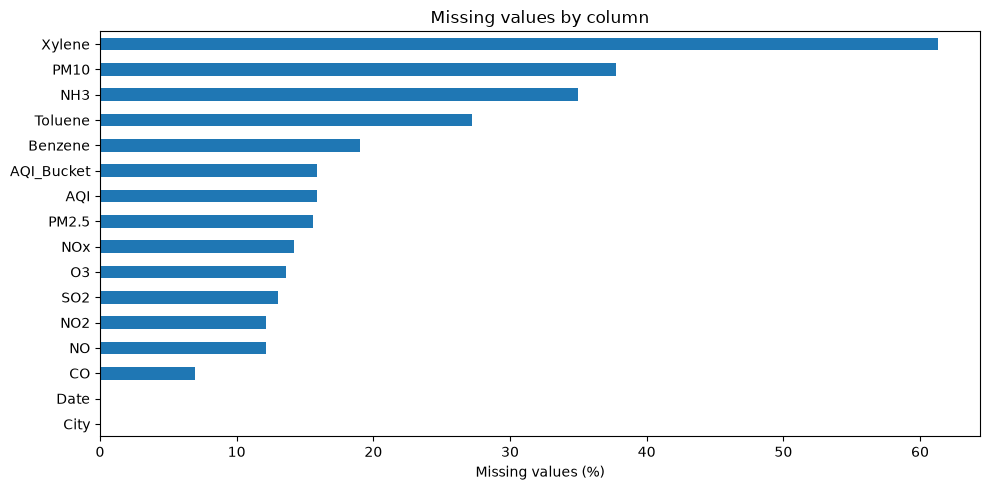

In [2]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

plt.figure(figsize=(10, 5))
missing_summary["missing_percent"].sort_values().plot(kind="barh")
plt.xlabel("Missing values (%)")
plt.title("Missing values by column")
plt.tight_layout()
plt.show()

### Interpretation

In this file, **AQI is missing in 4,681 rows (15.9%)**. `AQI_Bucket` has the same number of missing entries. **Xylene is missing in 18,109 rows (61.3%)**, so it is a particularly incomplete pollutant column.

Do not fill missing pollutant values with zero by default. Later, the handling method should depend on the analysis or model. For plots, each variable can use its available non-missing observations; for AQI analyses, rows without AQI cannot contribute an AQI value.

## 3. Duplicate records and coverage

There are two different checks:
- **Exact duplicate rows:** every column matches another row.
- **Duplicate city-date keys:** the same city and date occur more than once, even if some measurements differ.

The second check matters because city-day data is expected to have at most one record per city per date.

In [3]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated City-Date combinations:",
      df.duplicated(subset=["City", "Date"]).sum())
print("Invalid/missing dates after parsing:", df["Date"].isna().sum())

city_coverage = df.groupby("City").agg(
    total_rows=("Date", "size"),
    valid_AQI=("AQI", "count"),
    first_date=("Date", "min"),
    last_date=("Date", "max")
)
city_coverage["AQI_missing_percent"] = (
    100 * (1 - city_coverage["valid_AQI"] / city_coverage["total_rows"])
).round(1)

display(city_coverage.sort_values("total_rows", ascending=False))

Exact duplicate rows: 0
Repeated City-Date combinations: 0
Invalid/missing dates after parsing: 0


,total_rows,valid_AQI,first_date,last_date,AQI_missing_percent
City,,,,,
Ahmedabad,2009,1334,2015-01-01,2020-07-01,33.6
Bengaluru,2009,1910,2015-01-01,2020-07-01,4.9
Chennai,2009,1884,2015-01-01,2020-07-01,6.2
Mumbai,2009,775,2015-01-01,2020-07-01,61.4
Lucknow,2009,1893,2015-01-01,2020-07-01,5.8
Delhi,2009,1999,2015-01-01,2020-07-01,0.5
Hyderabad,2006,1880,2015-01-04,2020-07-01,6.3
Patna,1858,1459,2015-06-01,2020-07-01,21.5
Gurugram,1679,1453,2015-11-27,2020-07-01,13.5


### Interpretation

The supplied data has **zero exact duplicate rows** and **0 repeated city-date combinations**. That is reassuring for a daily city-level dataset.

Coverage differs between cities, and the number of rows is not always the same as the number of valid AQI readings. When comparing city averages, always inspect valid AQI counts and time coverage as well.

## 4. Descriptive statistics

The `describe()` table summarizes each numerical column:
- `count`: non-missing values
- `mean`: arithmetic average
- `std`: standard deviation (spread)
- `min` / `max`: extremes
- `25%`, `50%`, `75%`: quartiles; `50%` is the median

The mean and median can differ substantially when a distribution is skewed or contains extreme values.

In [4]:
numeric_summary = df.select_dtypes(include="number").describe().T
display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.45,64.66,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,118.13,90.61,0.01,56.26,95.68,149.74,1000.00
NO,25949.0,17.57,22.79,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,28.56,24.47,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,32.31,31.65,0.00,12.82,23.52,40.13,467.63
NH3,19203.0,23.48,25.68,0.01,8.58,15.85,30.02,352.89
CO,27472.0,2.25,6.96,0.00,0.51,0.89,1.45,175.81
SO2,25677.0,14.53,18.13,0.01,5.67,9.16,15.22,193.86
O3,25509.0,34.49,21.69,0.01,18.86,30.84,45.57,257.73
Benzene,23908.0,3.28,15.81,0.00,0.12,1.07,3.08,455.03


## 5. Plot pollutant and AQI distributions

Histograms show how often values fall into different ranges. AQI and pollutant measurements can be skewed, so a few very high readings may stretch the horizontal axis.

Use these plots to describe the data, not to label every high value as an error. Extreme pollution readings can be real.

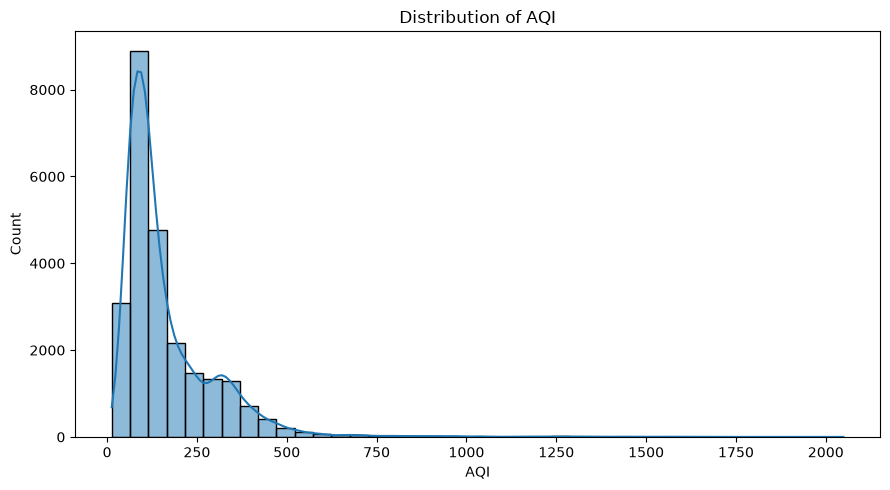

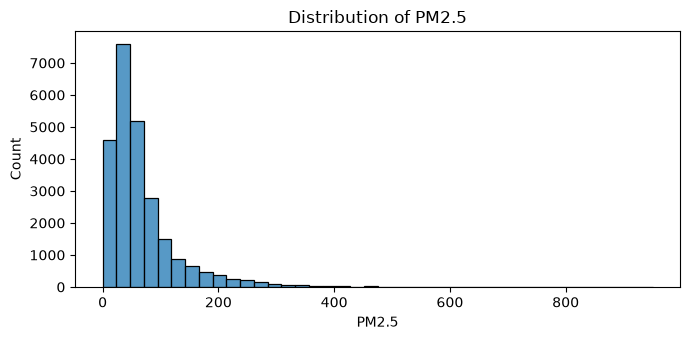

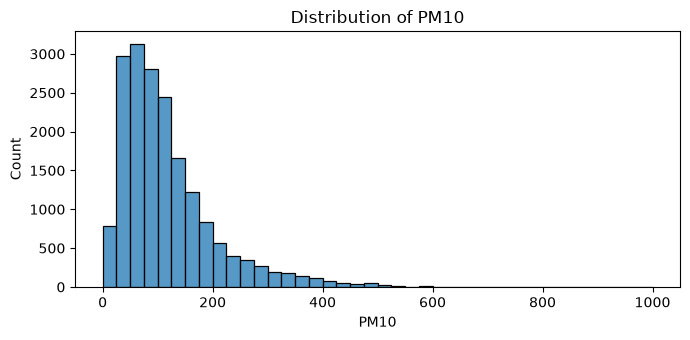

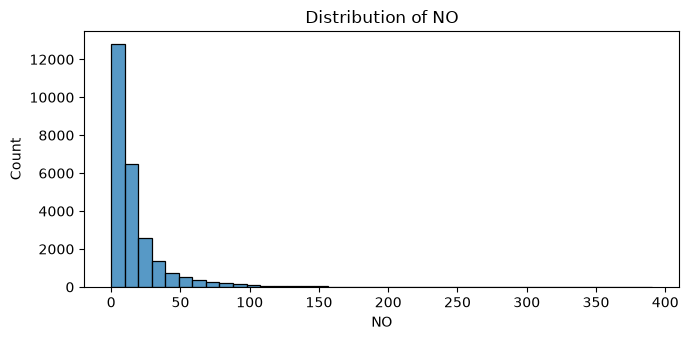

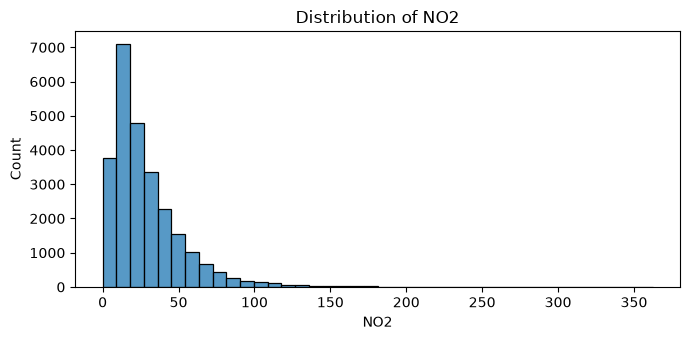

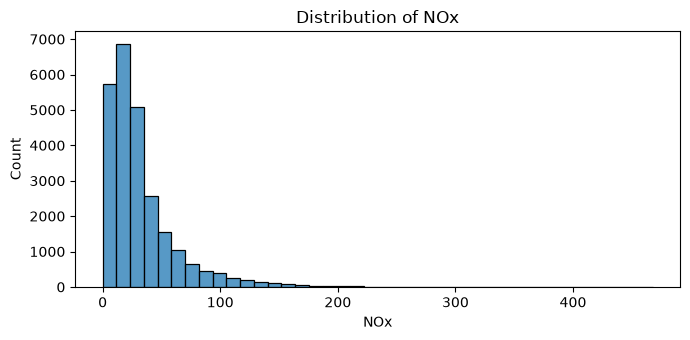

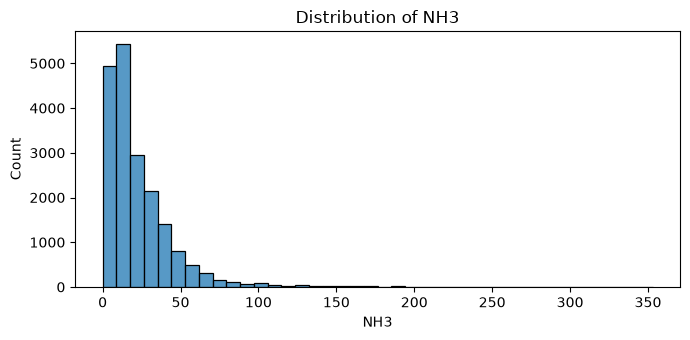

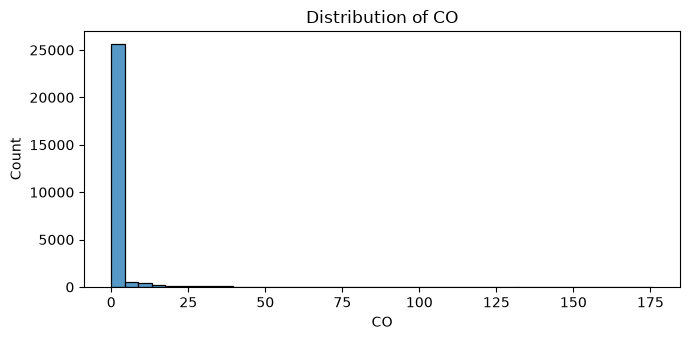

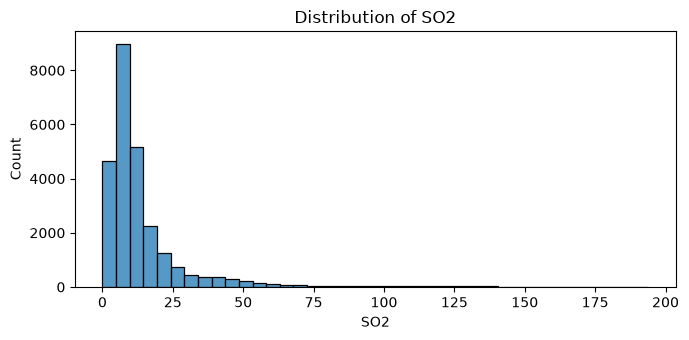

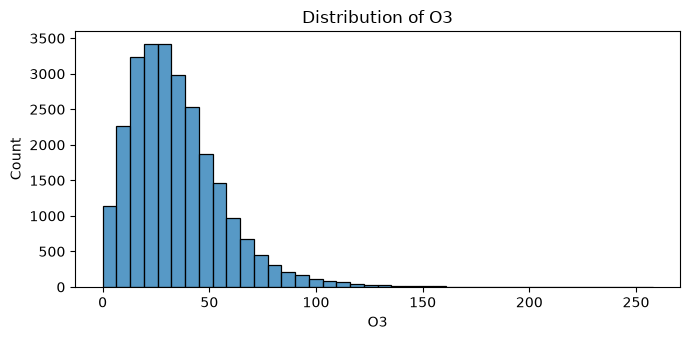

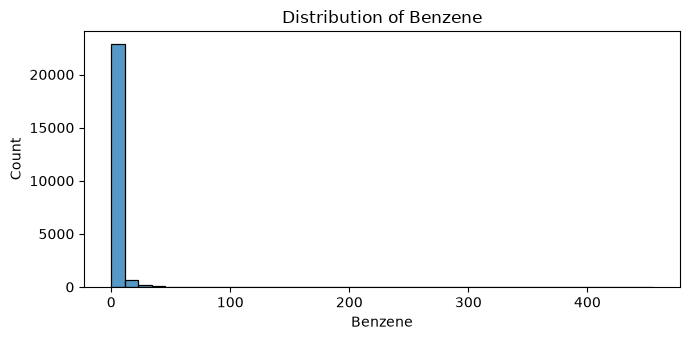

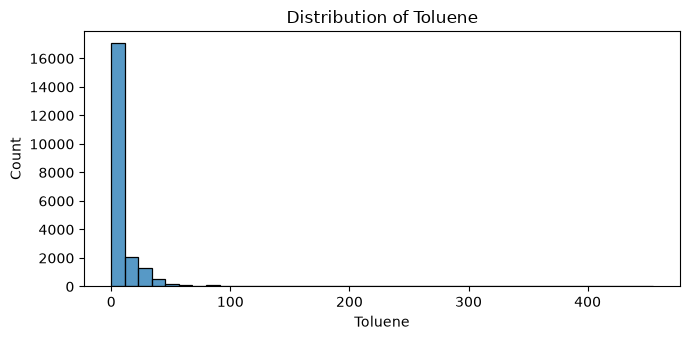

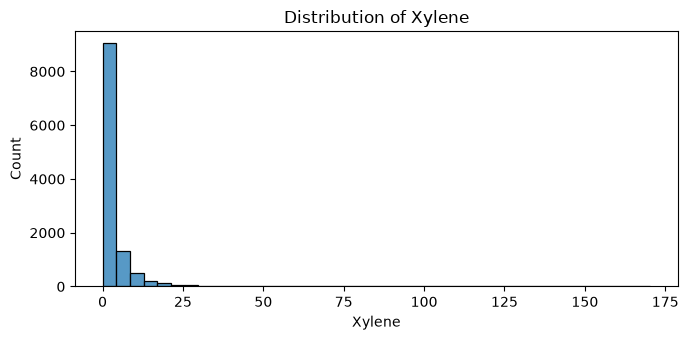

In [5]:
# AQI distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="AQI", bins=40, kde=True)
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.tight_layout()
plt.show()

# Pollutant distributions (one plot per variable)
pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

for col in pollutants:
    plt.figure(figsize=(7, 3.5))
    sns.histplot(data=df, x=col, bins=40)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

### What to look for

- Is the distribution roughly symmetric or does it have a long right tail?
- Are many observations concentrated in a narrow range?
- Are there unusually high values?
- Do the mean and median tell similar stories?

Do not try to make a conclusion from the histogram alone; use the summary statistics and data context too.

## 6. City-wise AQI comparison

Compare cities using valid AQI readings only. The bar chart below uses the mean AQI, while the table also shows the median and number of valid observations.

The mean can be affected by very high readings; the median is more resistant to extremes. Neither alone tells the whole story.

,total_rows,valid_AQI,mean_AQI,median_AQI
City,,,,
Ahmedabad,2009,1334,452.12,384.5
Delhi,2009,1999,259.49,257.0
Patna,1858,1459,240.78,215.0
Gurugram,1679,1453,225.12,208.0
Lucknow,2009,1893,217.97,198.0
Talcher,925,698,172.89,128.5
Jorapokhar,1169,771,159.25,133.0
Brajrajnagar,938,713,150.28,122.0
Kolkata,814,754,140.57,94.0


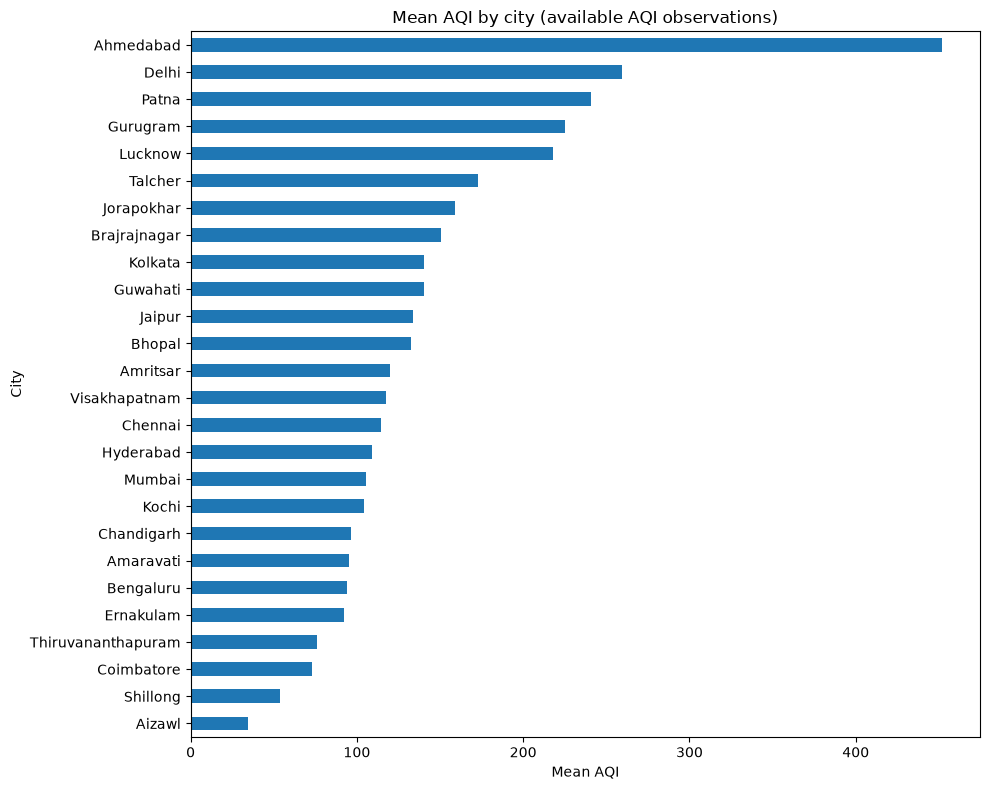

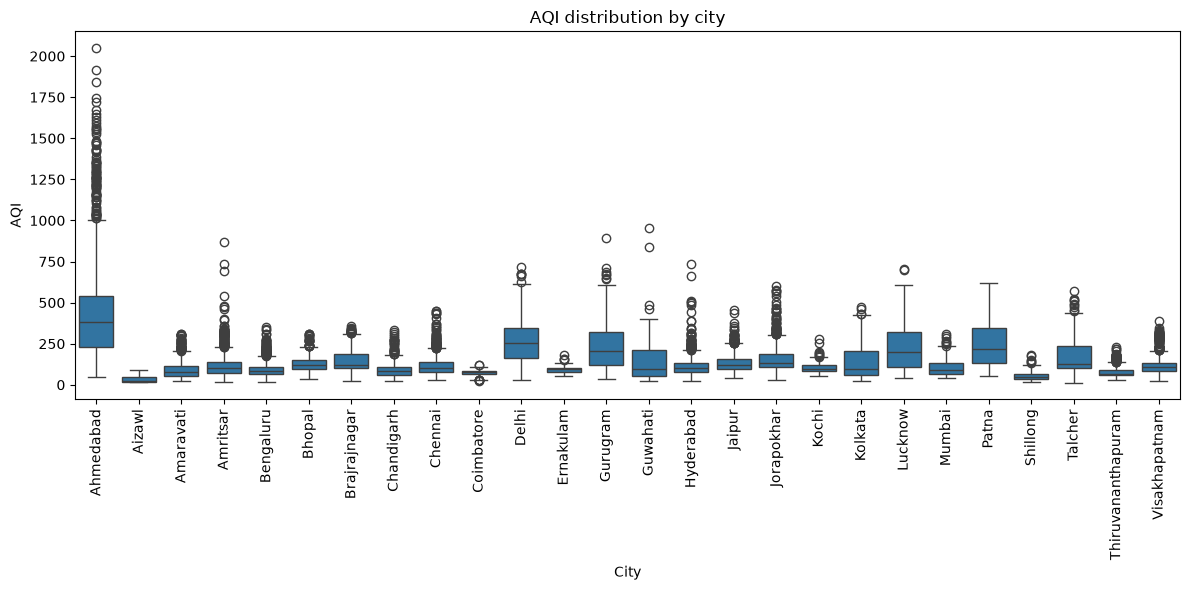

In [6]:
city_aqi = df.groupby("City").agg(
    total_rows=("AQI", "size"),
    valid_AQI=("AQI", "count"),
    mean_AQI=("AQI", "mean"),
    median_AQI=("AQI", "median")
).sort_values("mean_AQI", ascending=False)

display(city_aqi.round(2))

plt.figure(figsize=(10, 8))
city_aqi["mean_AQI"].sort_values().plot(kind="barh")
plt.xlabel("Mean AQI")
plt.title("Mean AQI by city (available AQI observations)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="City", y="AQI")
plt.xticks(rotation=90)
plt.title("AQI distribution by city")
plt.tight_layout()
plt.show()

### Interpretation from the supplied data

Using all available AQI observations, **Ahmedabad has the highest raw city mean (452.1)**, while **Aizawl has the lowest (34.8)** in this file.

Treat this as a descriptive result, not a definitive ranking of long-term city air quality. The cities have different numbers of valid observations and potentially different date coverage. The box plot helps show within-city spread, not just the average.

## 7. Pollutant correlations

Correlation measures how strongly two numerical variables move together in a linear way. Positive correlation means they tend to increase together; negative correlation means one tends to increase as the other decreases.

**Correlation is not causation.** It also does not automatically mean that one feature should be removed. We will use this analysis to understand the data first.

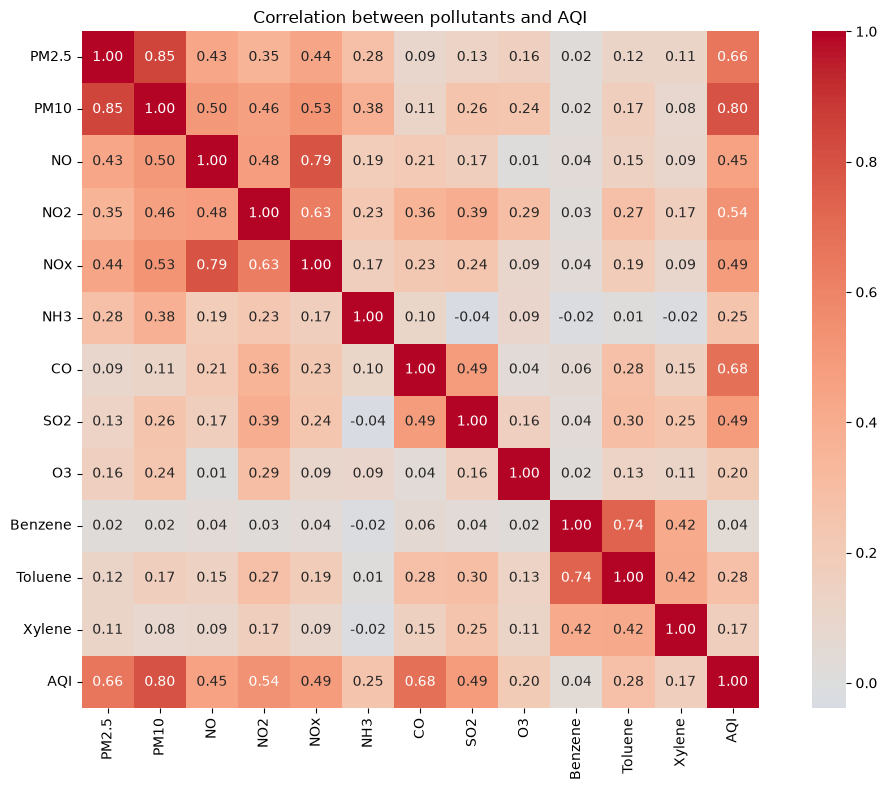

Correlation with AQI:


,correlation_with_AQI
PM10,0.803313
CO,0.683346
PM2.5,0.659181
NO2,0.537071
SO2,0.490586
NOx,0.486450
NO,0.452191
Toluene,0.279992
NH3,0.252019
O3,0.198991


In [7]:
corr_cols = pollutants + ["AQI"]
correlation = df[corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=True,
            fmt=".2f", square=True)
plt.title("Correlation between pollutants and AQI")
plt.tight_layout()
plt.show()

print("Correlation with AQI:")
display(correlation["AQI"].drop("AQI").sort_values(ascending=False).to_frame("correlation_with_AQI"))

### Interpretation from the supplied data

In this file, the strongest positive linear correlation with AQI among these numerical columns is **PM10 (r = 0.803)**. This is an association in this dataset; it does not establish that the pollutant alone causes the AQI value.

Because AQI is calculated from pollutant measurements under an AQI methodology, strong associations are not surprising. If we later model AQI from the same-day pollutant values, we must describe the task as estimating AQI from measurements—not as forecasting future AQI.

## 8. Time-series EDA: monthly and yearly patterns

Time-series EDA asks how a variable changes over time. Here we will:
1. Create date-derived columns.
2. Plot the overall AQI timeline.
3. Calculate monthly and yearly average AQI.
4. Compare seasonal patterns.

For the monthly time series, the mean is calculated from the AQI values available in each month. A month with fewer observations may be less representative, so counts should be checked too.

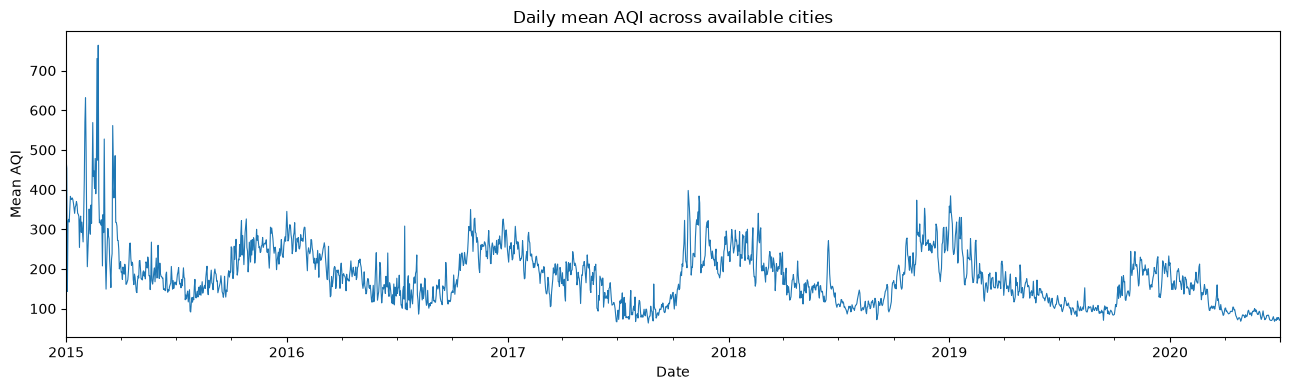

,mean_AQI,valid_AQI
Month,,
1,231.67,2141
2,202.91,2078
3,164.74,2327
4,143.36,2295
5,135.49,2447
6,120.20,2344
7,111.85,1836
8,113.61,1776
9,115.19,1757


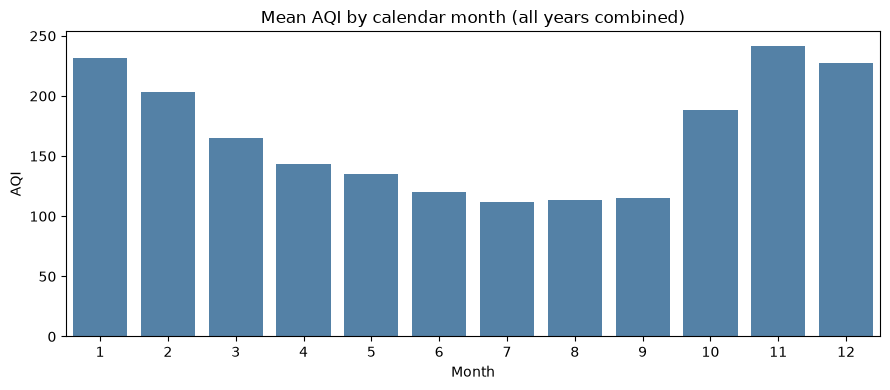

,mean_AQI,valid_AQI
Year,,
2015,212.46,1827
2016,197.15,2573
2017,181.47,3234
2018,182.68,5724
2019,156.52,7071
2020,113.52,4421


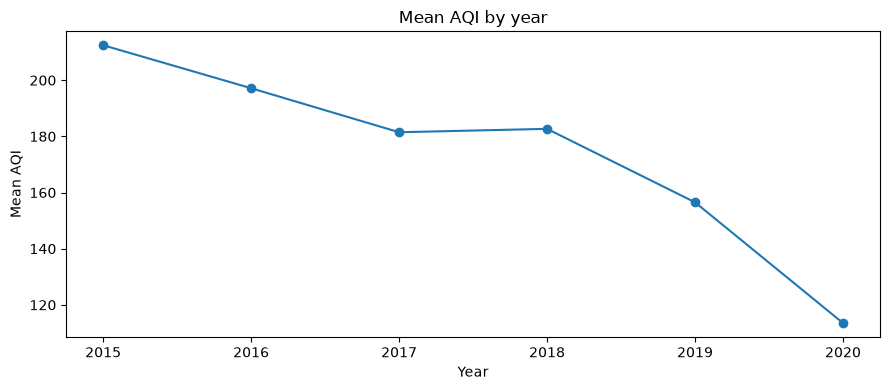

In [8]:
# Create useful calendar features from Date
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Weekday"] = df["Date"].dt.day_name()

# Overall daily AQI timeline (across all available city readings)
daily_aqi = df.groupby("Date")["AQI"].mean()

plt.figure(figsize=(13, 4))
daily_aqi.plot(linewidth=0.8)
plt.title("Daily mean AQI across available cities")
plt.ylabel("Mean AQI")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

# Monthly average and number of available AQI records
monthly_aqi = df.groupby("Month").agg(
    mean_AQI=("AQI", "mean"),
    valid_AQI=("AQI", "count")
)
display(monthly_aqi.round(2))

plt.figure(figsize=(9, 4))
sns.barplot(data=df, x="Month", y="AQI", errorbar=None, color="steelblue")
plt.title("Mean AQI by calendar month (all years combined)")
plt.tight_layout()
plt.show()

# Yearly summary
yearly_aqi = df.groupby("Year").agg(
    mean_AQI=("AQI", "mean"),
    valid_AQI=("AQI", "count")
)
display(yearly_aqi.round(2))

plt.figure(figsize=(9, 4))
yearly_aqi["mean_AQI"].plot(marker="o")
plt.title("Mean AQI by year")
plt.ylabel("Mean AQI")
plt.tight_layout()
plt.show()

### Important interpretation cautions

- The last year in the file is **2020**, and its data ends on July 1. It is not a full year, so don't compare its annual mean with complete years without noting this.
- The overall daily mean gives each available city observation equal weight; it is not necessarily a population-weighted measure of India's air quality.
- Calendar-month averages combine all years. They can hide year-to-year differences.
- Seasonal or festival indicators should be added only with a clear definition and justification. A date alone does not tell us whether a local festival occurred.
- These plots describe historical patterns. They do not, by themselves, forecast future AQI.

## 9. City-specific monthly trends

A national/overall average can hide differences between cities. This plot compares monthly mean AQI for a few cities with substantial data coverage. The selected cities are illustrative and can be changed.

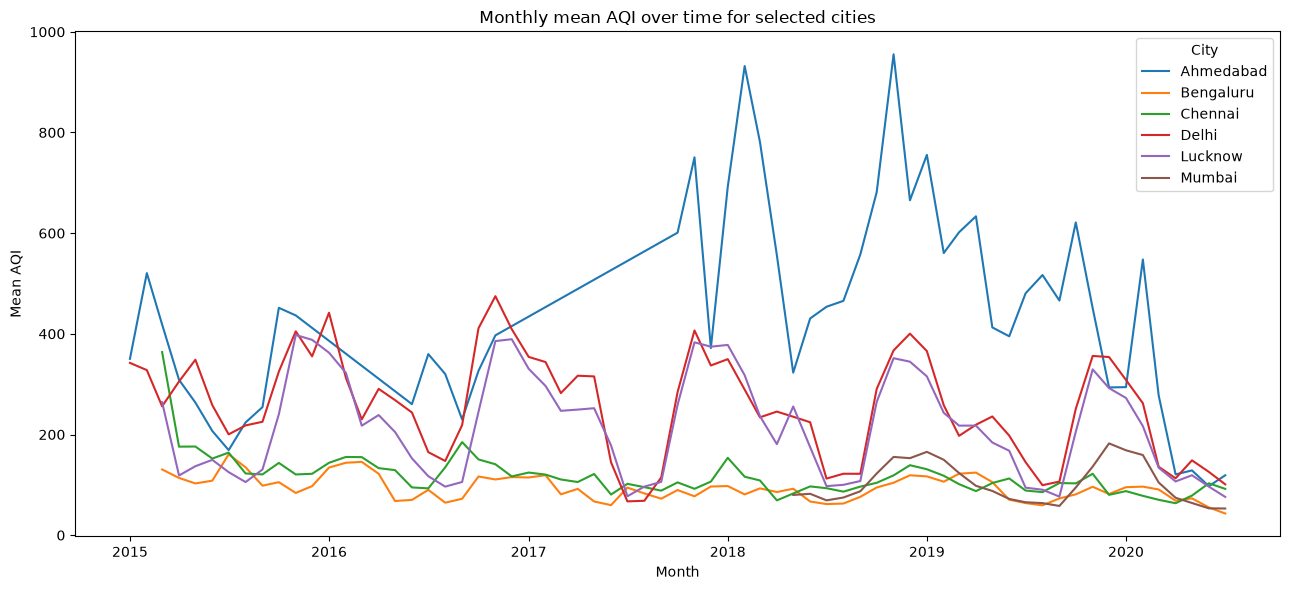

In [9]:
selected_cities = ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Lucknow", "Ahmedabad"]
city_month = (
    df[df["City"].isin(selected_cities)]
    .groupby(["City", "Year", "Month"], as_index=False)["AQI"]
    .mean()
)
city_month["YearMonth"] = pd.to_datetime(
    city_month["Year"].astype(str) + "-" +
    city_month["Month"].astype(str).str.zfill(2) + "-01"
)

plt.figure(figsize=(13, 6))
sns.lineplot(data=city_month, x="YearMonth", y="AQI", hue="City")
plt.title("Monthly mean AQI over time for selected cities")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.tight_layout()
plt.show()

## 10. Key findings and limitations

Use the results above to write a short summary in your own words. A good EDA conclusion should state what the data shows and what it cannot establish.

Points to check:
- Which columns have the most missing data?
- Which cities have the most and least valid AQI records?
- Are pollutant distributions skewed?
- Which pollutants are most strongly correlated with AQI in this dataset?
- Do monthly/yearly patterns appear, and are there coverage limitations?
- Are some cities underrepresented or observed over shorter periods?

### Data-quality reminders
- Missing values are not zeros.
- No exact duplicate rows does not guarantee every city-date key is unique.
- High values are not automatically errors.
- City means can be affected by different date coverage.
- Correlation does not imply causation.

### Next stage
After this notebook, the next tasks are to decide on cleaning rules and implement the required SQLite operations. Model training, feature reduction, regression and classification belong to later stages.